In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import os
cores_count = os.cpu_count()

In [3]:
from datetime import date, datetime, timedelta
from dateutil.rrule import rrule, DAILY

from matplotlib import pyplot
%matplotlib inline

import numpy as np
import pandas as pd

import scipy.stats as ss
from sklearn import linear_model
import statsmodels.api as sm

In [4]:
df_vitals = pd.read_csv('combined_vitals.csv')

In [5]:
#convert the timestamp field from string to datetime data type
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'],errors='coerce')

In [6]:
# keep only the required fields 
df_vitals=df_vitals[['patient_uuid','timestamp','HR','SBP','DBP']]

In [7]:
df_vitals.head()

,patient_uuid,timestamp,HR,SBP,DBP
0,82591262,2015-12-31 23:08:00,67.0,161.0,112.0
1,82591262,2018-10-09 13:40:00,80.0,111.0,72.0
2,82591262,2018-10-09 17:39:00,79.0,134.0,84.0
3,82591262,2018-10-09 17:40:00,79.0,126.0,79.0
4,82591262,2018-10-10 08:07:00,53.0,137.0,88.0


In [8]:
# remove entries older than 01-Oct-2018 and newer than 14-Jan-2020. This step may or may not be needed.
# retaining it as-is for now
df_vitals=df_vitals[(df_vitals.timestamp>'2018-10-01')&(df_vitals.timestamp<'2020-01-14')]

# remove all na entries
df_vitals=df_vitals[~df_vitals['DBP'].isna()]
df_vitals=df_vitals[~df_vitals['SBP'].isna()]
df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [9]:
# Let's start our analysis with the Systolic Blood Pressure. 
df_vitals_hr = df_vitals[['timestamp','patient_uuid','HR']]

In [10]:
df_vitals_hr

,timestamp,patient_uuid,HR
1,2018-10-09 13:40:00,82591262,80.0
2,2018-10-09 17:39:00,82591262,79.0
3,2018-10-09 17:40:00,82591262,79.0
4,2018-10-10 08:07:00,82591262,53.0
5,2018-10-10 14:02:00,82591262,71.0
...,...,...,...
340960,2020-01-10 08:27:00,81827529,53.0
340961,2020-01-10 12:46:00,81827529,58.0
340962,2020-01-11 07:39:00,81827529,57.0
340963,2020-01-13 08:47:00,81827529,56.0


In [11]:
df_vitals_hr_day = df_vitals_hr

df_vitals_hr_day['reading_date'] = [dt.date() for dt in df_vitals_hr_day.timestamp]

df_vitals_hr_day['reading_date'] = pd.to_datetime(df_vitals_hr_day['reading_date'])

df_vitals_hr_day = df_vitals_hr_day.groupby(['patient_uuid','reading_date']).filter(lambda x : len(x)>1)
df_vitals_hr_day

,timestamp,patient_uuid,HR,reading_date
1,2018-10-09 13:40:00,82591262,80.0,2018-10-09
2,2018-10-09 17:39:00,82591262,79.0,2018-10-09
3,2018-10-09 17:40:00,82591262,79.0,2018-10-09
4,2018-10-10 08:07:00,82591262,53.0,2018-10-10
5,2018-10-10 14:02:00,82591262,71.0,2018-10-10
...,...,...,...,...
340959,2020-01-08 12:06:00,81827529,56.0,2020-01-08
340960,2020-01-10 08:27:00,81827529,53.0,2020-01-10
340961,2020-01-10 12:46:00,81827529,58.0,2020-01-10
340963,2020-01-13 08:47:00,81827529,56.0,2020-01-13


In [12]:
df_vitals_hr_day = pd.DataFrame(df_vitals_hr_day.groupby(['patient_uuid','reading_date']).agg({'HR' : np.mean}))
df_vitals_hr_day = df_vitals_hr_day.reset_index(level=[0,1])
df_vitals_hr_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_hr_day['source'] = 1

In [13]:
df_vitals_hr_day

,patient_uuid,reading_date,HR,source
0,1048697,2019-08-26,80.000000,1
1,1048697,2019-08-27,92.666667,1
2,1048697,2019-08-28,84.500000,1
3,1048697,2019-08-29,84.333333,1
4,1048697,2019-08-30,91.500000,1
...,...,...,...,...
95083,99726731,2019-03-18,60.000000,1
95084,99726731,2019-03-19,59.000000,1
95085,99726731,2019-03-21,56.000000,1
95086,99726731,2019-03-22,79.000000,1


In [ ]:
# extend the dataset to have a new field 
# that contains the date time value of the very first measurement available for each patient
# this information will later be used to derive additional column values of interest

df_vitals_hr_minmaxtimes = pd.DataFrame(df_vitals_hr.groupby('patient_uuid').agg({'timestamp' : np.min}))
df_vitals_hr_minmaxtimes['timestamp'] = df_vitals_hr_minmaxtimes['timestamp']

df_vitals_hr_extended = pd.merge(df_vitals_hr, df_vitals_hr_minmaxtimes, on='patient_uuid')
df_vitals_hr_extended['reading_date'] = pd.to_datetime(df_vitals_hr_extended['reading_date'])
df_vitals_hr_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)

In [ ]:
df_vitals_hr_extended

In [ ]:
# In the extended dataset, add two additional columns that have the measurement date (without the time)
# and the start date (without the time)
# Again, this information will be used subsequently to derive additional features of interest
df_vitals_hr_extended['reading_date'] = [dt.date() for dt in df_vitals_hr_extended.timestamp_x]
df_vitals_hr_extended['reading_date'] = pd.to_datetime(df_vitals_hr_extended['reading_date'])
df_vitals_hr_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_hr_extended['reading_start_date'] = [dt.date() for dt in df_vitals_hr_extended.timestamp_y]
df_vitals_hr_extended['reading_start_date'] = pd.to_datetime(df_vitals_hr_extended['reading_start_date'])

In [ ]:
# for every reading, get the days elapsed since the first measurement date (note this is in days)
df_vitals_hr_extended['days_elapsed'] = (df_vitals_hr_extended['reading_date'] - df_vitals_hr_extended['reading_start_date']).dt.days
df_vitals_hr_extended['log_days_elapsed'] = np.log(df_vitals_hr_extended['days_elapsed'])/10
df_vitals_hr_extended.loc[df_vitals_hr_extended.days_elapsed == 0,'log_days_elapsed'] = 0

In [ ]:
# convert the new time stamp columns to date time data type
df_vitals_hr_extended['timestamp_x'] = pd.to_datetime(df_vitals_hr_extended['timestamp_x'])
df_vitals_hr_extended['timestamp_y'] = pd.to_datetime(df_vitals_hr_extended['timestamp_y'])

In [ ]:
# Now, from the time component, get the hours since mid night for each measurement
# and extend it further to get the corresponding angle (24 hours = 360 degress, x hours = x*360/24)

df_vitals_hr_extended['elapsed_time'] = df_vitals_hr_extended['timestamp_x'] - df_vitals_hr_extended['reading_date']
df_vitals_hr_extended['angle'] = df_vitals_hr_extended['elapsed_time'].diff() *360 / (np.timedelta64(1, 'h') *24)

# get the cosine and sine values corresponding to these angles
df_vitals_hr_extended['sine'] = np.sin(df_vitals_hr_extended['angle'])
df_vitals_hr_extended['cos'] = np.cos(df_vitals_hr_extended['angle'])

# drop NA
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['sine'].isna()]
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['cos'].isna()]


# get the cosine and sine values corresponding to the angles with a period T/2 = 12 hours
df_vitals_hr_extended['sine.Tby2'] = np.sin(df_vitals_hr_extended['angle']*2)
df_vitals_hr_extended['cos.Tby2'] = np.cos(df_vitals_hr_extended['angle']*2)

# drop NA
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['sine.Tby2'].isna()]
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['cos.Tby2'].isna()]

# get the cosine and sine values corresponding to the angles with a period T/3 = 8 hours
df_vitals_hr_extended['sine.Tby3'] = np.sin(df_vitals_hr_extended['angle']*3)
df_vitals_hr_extended['cos.Tby3'] = np.cos(df_vitals_hr_extended['angle']*3)

# drop NA
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['sine.Tby3'].isna()]
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['cos.Tby3'].isna()]

# get the cosine and sine values corresponding to the angles with a period T/6 = 4 hours
df_vitals_hr_extended['sine.Tby6'] = np.sin(df_vitals_hr_extended['angle']*6)
df_vitals_hr_extended['cos.Tby6'] = np.cos(df_vitals_hr_extended['angle']*6)

# drop NA
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['sine.Tby6'].isna()]
df_vitals_hr_extended=df_vitals_hr_extended[~df_vitals_hr_extended['cos.Tby6'].isna()]

In [ ]:
df_vitals_hr_extended

In [ ]:
# create a new column and extract the information on days between the current measurement and the previous measurement
df_vitals_hr_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_hr_extended['days_between_readings'] = -999

for patient_uuid in df_vitals_hr_extended['patient_uuid'].unique():
    df_vitals_hr_extended.loc[df_vitals_hr_extended.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_hr_extended[df_vitals_hr_extended.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_hr_extended[df_vitals_hr_extended.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

In [ ]:
# review this data for one patient just to make sure that the derived columns have the correct values
df_vitals_hr_extended[df_vitals_hr_extended.patient_uuid == 82591262]

In [ ]:
# Now, we will split the measurements for each patients into multiple batches
# the batch contains successive measurements with a gap of no more than 3 days between two readings
# If the gap is higher, then there could be a big change that will throw off the interpolation
# the 3 here is a hyperparameter which may need to be tuned
df_vitals_hr_extended.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_hr_extended['batch'] = 0

df_vitals_hr_extended.loc[df_vitals_hr_extended['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_hr_extended['patient_uuid'].unique():
    df_vitals_hr_extended.loc[df_vitals_hr_extended.patient_uuid == patient_uuid,'batch'] = df_vitals_hr_extended[df_vitals_hr_extended.patient_uuid == patient_uuid]['batch'].cumsum()

In [ ]:
df_vitals_hr_extended.head(600)

In [ ]:
df_vitals_hr_extended_patient = df_vitals_hr_extended[df_vitals_hr_extended['patient_uuid']==1048697]

In [ ]:
df_vitals_hr_extended_patient.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in df_vitals_hr_extended_patient['patient_uuid'].unique():
    vitals_hr_interpolated_patient = df_vitals_hr_extended_patient[df_vitals_hr_extended_patient['patient_uuid']==patient_uuid]
    vitals_hr_interpolated_patient['reading_date'] = pd.to_datetime(vitals_hr_interpolated_patient['reading_date'])
        
    vitals_hr_interpolated_patient['days_difference'] = vitals_hr_interpolated_patient['reading_date'].shift(-1) - vitals_hr_interpolated_patient['reading_date']
    print(vitals_hr_interpolated_patient)
    break

Y = M + a * cos(theta) + b * sin(theta) + c * cos(theta*2) + d * sin(theta*2) + e * cos(theta*3) + f * sin(theta*2) + g * cos(theta*6) + h * sin(theta*6) + i*log(days_elapsed)

To identify the median, we find the min and max, which happens when:

d/dt [a*cos(t) + b*sin(t)] = 0

-a*sin(t)+b*cos(t) = 0

a*sin(t)=b*cos(t)

tan(t) = b/a

t = taninv(b/a)

Y(max) for a given day = M + Max(x+y) + B

Y(min) for a given day = M + Min(x+y) + B

Here x=a*cos(t), y = b*sin(t), B = c*days_elapsed

Note, B varies over days due to days_elapsed

So, Ymedian for a day = [Max(x+y)+Min(x+y)]/2 + c*days_elapsed, which is also equal to M+Min(x+y)

Note, Median may not be equal to intercept since intercept in this case is only ...although for simplicity we can just go with the intercept





In [ ]:
# the mathematical expression for the model is: 
# Y = M + a * cos(theta) + b * sin(theta) + c * cos(theta*2) + d * sin(theta*2) + e * cos(theta*3) + f * sin(theta*2) + g * cos(theta*6) + h * sin(theta*6) + i*days_elapsed
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
df_vitals_interpolated = pd.DataFrame(columns = ['patient_uuid','reading_date','HR'])
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date'])
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'], inplace=True)
loopcount = len(df_vitals_hr_extended['patient_uuid'].unique())
currloop = 0
for patient_uuid in df_vitals_hr_extended['patient_uuid'].unique():
    print(str(currloop) + ' out of ' + str(loopcount) + ', patient_uuid = ' + str(patient_uuid) )
    currloop = currloop + 1
    df_vitals_subset = df_vitals_hr_extended[df_vitals_hr_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        df_vitals_subset_batch['reading_date'] = pd.to_datetime(df_vitals_subset_batch['reading_date'])
        df_vitals_subset_batch.sort_values(by=['patient_uuid','reading_date'],inplace=True)
        #if df_vitals_subset_batch.shape[0] > 1:
        X = df_vitals_subset_batch[['cos','sine','cos.Tby2','sine.Tby2','days_elapsed']]
        y = df_vitals_subset_batch[['HR']]
        lm = linear_model.LinearRegression(n_jobs=cores_count)
        model = lm.fit(X,y)
        #print(df_vitals_subset_batch.agg({'reading_date' : np.min}))
        min_batch_date = pd.to_datetime(df_vitals_subset_batch.agg({'reading_date' : np.min}))
        max_batch_date = pd.to_datetime(df_vitals_subset_batch.agg({'reading_date' : np.max}))
        total_days = int((max_batch_date - min_batch_date).to_string().split(' ')[3])
        for days_elapsed in np.arange(0,total_days,1):
            HR_interpolated = float(lm.intercept_) + float(lm.coef_[0][4]) * days_elapsed
            reading_date = pd.to_datetime((min_batch_date + pd.DateOffset(days=days_elapsed)).to_string().split('   ')[1])
            #print(reading_date)
            df_vitals_interpolated.loc[len(df_vitals_interpolated)] = [patient_uuid, reading_date, HR_interpolated]
            days_elapsed = days_elapsed + 1
            
        #break
    #break
print('Interpolation Procedure completed')

In [ ]:
df_vitals_hr_day = pd.merge(df_vitals_hr_day, df_vitals_interpolated,on=['patient_uuid','reading_date'],how='inner')

In [ ]:
df_vitals_hr_day = df_vitals_hr_day[['patient_uuid','reading_date','HR_x','source_x']]

df_vitals_hr_day.rename(columns={'HR_x':'HR','source_x':'source'},inplace=True)

df_vitals_hr_day

In [ ]:
print(df_vitals_interpolated.shape)

df_vitals_interpolated.to_csv("vitals_hr_interpolated_dataset.csv", index = False)

In [14]:
df_vitals_interpolated = pd.read_csv('vitals_hr_interpolated_dataset.csv')

In [15]:
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date'])

df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'],inplace=True)

df_vitals_interpolated_minmaxtimes = pd.DataFrame(df_vitals_interpolated.groupby('patient_uuid').agg({'reading_date' : np.min}))

df_vitals_interpolated_minmaxtimes.rename(columns={'reading_date':'reading_start_date'},inplace=True)

df_vitals_interpolated_final = pd.merge(df_vitals_interpolated, df_vitals_interpolated_minmaxtimes, on='patient_uuid')

df_vitals_interpolated_final['reading_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_date'])

df_vitals_interpolated_final.sort_values(by=['patient_uuid','reading_date'],inplace=True)

df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days

df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 1,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','HR']]

In [16]:
df_vitals_interpolated = df_vitals_interpolated_final

In [17]:
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in df_vitals_interpolated['patient_uuid'].unique():
    vitals_hr_interpolated_patient = df_vitals_interpolated[df_vitals_interpolated['patient_uuid']==patient_uuid]
    for batch in vitals_hr_interpolated_patient['batch'].unique():
        vitals_hr_interpolated_patient_batch = vitals_hr_interpolated_patient[vitals_hr_interpolated_patient['batch']==batch]
        vitals_hr_interpolated_patient_batch['reading_date'] = pd.to_datetime(vitals_hr_interpolated_patient_batch['reading_date'])
        vitals_hr_interpolated_patient_batch['next_reading_date'] = vitals_hr_interpolated_patient_batch['reading_date'].shift(-1)
        #print(int((vitals_hr_interpolated_patient_batch['next_reading_date'] - vitals_hr_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
        vitals_hr_interpolated_patient_batch['days_difference'] = (vitals_hr_interpolated_patient_batch['next_reading_date'] - vitals_hr_interpolated_patient_batch['reading_date'])
        #print(vitals_hr_interpolated_patient_batch.dtypes)
        row_count_with_days_diff = vitals_hr_interpolated_patient_batch[vitals_hr_interpolated_patient_batch['days_difference']>timedelta(days=1)].shape[0]
        if row_count_with_days_diff > 0:
            print(vitals_hr_interpolated_patient_batch[vitals_hr_interpolated_patient_batch['days_difference']>timedelta(days=1)])
    #break

In [18]:
#df_vitals_interpolated = df_vitals_interpolated[(df_vitals_interpolated.HR>0)]
df_vitals_interpolated.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_interpolated['source'] = 2

df_vitals_interpolated = df_vitals_interpolated[['patient_uuid','reading_date','HR','source']]
df_vitals_interpolated

,patient_uuid,reading_date,HR,source
0,1048697,2019-08-26,86.525558,2
1,1048697,2019-08-27,86.533354,2
2,1048697,2019-08-28,86.541150,2
3,1048697,2019-08-29,86.548947,2
4,1048697,2019-08-30,86.556743,2
...,...,...,...,...
152503,99814066,2020-01-08,97.283923,2
152504,99814066,2020-01-09,93.460395,2
152505,99814066,2020-01-10,89.636867,2
152506,99814066,2020-01-11,85.813338,2


In [19]:
#df_vitals_hr_day = df_vitals_hr_day.reset_index(level=[0])
df_vitals_hr_day.sort_values(by=['patient_uuid','reading_date'],inplace=True)
df_vitals_hr_day

,patient_uuid,reading_date,HR,source
0,1048697,2019-08-26,80.000000,1
1,1048697,2019-08-27,92.666667,1
2,1048697,2019-08-28,84.500000,1
3,1048697,2019-08-29,84.333333,1
4,1048697,2019-08-30,91.500000,1
...,...,...,...,...
95083,99726731,2019-03-18,60.000000,1
95084,99726731,2019-03-19,59.000000,1
95085,99726731,2019-03-21,56.000000,1
95086,99726731,2019-03-22,79.000000,1


In [20]:
print(df_vitals_hr_day.shape)

print(df_vitals_interpolated.shape)

(95088, 4)
(152508, 4)


In [21]:
df_vitals_interpolated

,patient_uuid,reading_date,HR,source
0,1048697,2019-08-26,86.525558,2
1,1048697,2019-08-27,86.533354,2
2,1048697,2019-08-28,86.541150,2
3,1048697,2019-08-29,86.548947,2
4,1048697,2019-08-30,86.556743,2
...,...,...,...,...
152503,99814066,2020-01-08,97.283923,2
152504,99814066,2020-01-09,93.460395,2
152505,99814066,2020-01-10,89.636867,2
152506,99814066,2020-01-11,85.813338,2


In [22]:
df_vitals_hr_day.patient_uuid = df_vitals_hr_day.patient_uuid.astype(int)
df_vitals_hr_day.HR = df_vitals_hr_day.HR.astype(float)
df_vitals_hr_day.source = df_vitals_hr_day.source.astype(int)
df_vitals_hr_day['reading_date'] = pd.to_datetime(df_vitals_hr_day['reading_date']) 

df_vitals_interpolated.patient_uuid = df_vitals_interpolated.patient_uuid.astype(int)
df_vitals_interpolated.HR = df_vitals_interpolated.HR.astype(float)
df_vitals_interpolated.source = df_vitals_interpolated.source.astype(int)
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date']) 

In [23]:
df_vitals_interpolated.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
HR                     float64
source                   int32
dtype: object

In [24]:
df_vitals_hr_day.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
HR                     float64
source                   int32
dtype: object

In [25]:
df_vitals_interpolated_new_values = pd.merge(df_vitals_hr_day, df_vitals_interpolated,on=['patient_uuid','reading_date'],how='right')

In [26]:
df_vitals_interpolated_new_values=df_vitals_interpolated_new_values[(df_vitals_interpolated_new_values['HR_x'].isna())|(df_vitals_interpolated_new_values['source_x'].isna())]

df_vitals_interpolated_new_values = df_vitals_interpolated_new_values[['patient_uuid','reading_date','HR_y']]

In [27]:
df_vitals_interpolated_new_values.shape

(58874, 3)

In [28]:
df_vitals_interpolated[df_vitals_interpolated['patient_uuid']==82591262]

,patient_uuid,reading_date,HR,source
126277,82591262,2018-10-09,63.019295,2
126278,82591262,2018-10-10,63.239317,2
126279,82591262,2018-10-11,63.459339,2
126280,82591262,2018-10-12,63.679361,2
126281,82591262,2018-10-13,63.899382,2
126282,82591262,2018-10-14,64.119404,2
126283,82591262,2018-10-15,64.339426,2
126284,82591262,2018-10-16,64.559448,2
126285,82591262,2018-10-17,64.779469,2
126286,82591262,2018-10-18,64.999491,2


In [29]:
df_vitals_interpolated_new_values[df_vitals_interpolated_new_values['patient_uuid']==82591262]

,patient_uuid,reading_date,HR_y
142238,82591262,2018-10-16,64.559448
142239,82591262,2018-10-17,64.779469
142240,82591262,2018-10-18,64.999491
142241,82591262,2018-10-19,65.219513
142242,82591262,2018-10-20,65.439535
142243,82591262,2018-10-28,67.199709
142244,82591262,2018-11-03,68.519839
142245,82591262,2018-11-04,68.739861
142246,82591262,2018-11-05,68.959883
142247,82591262,2018-11-06,69.179905


In [30]:
df_vitals_hr_day[df_vitals_hr_day['patient_uuid']==82591262]

,patient_uuid,reading_date,HR,source
78882,82591262,2018-10-09,79.333333,1
78883,82591262,2018-10-10,66.250000,1
78884,82591262,2018-10-11,66.333333,1
78885,82591262,2018-10-12,67.250000,1
78886,82591262,2018-10-13,65.750000,1
78887,82591262,2018-10-14,49.500000,1
78888,82591262,2018-10-15,59.000000,1
78889,82591262,2018-10-21,66.000000,1
78890,82591262,2018-10-22,73.500000,1
78891,82591262,2018-10-23,59.000000,1


In [31]:
df_vitals_hr_day = df_vitals_hr_day[['patient_uuid','reading_date','HR']]

df_vitals_interpolated_new_values.rename(columns={"HR_y":"HR"},inplace=True)

In [32]:
df_vitals_interpolated_final = pd.concat([df_vitals_hr_day,df_vitals_interpolated_new_values])

In [33]:
df_vitals_interpolated_final.shape

(153962, 3)

In [34]:
df_vitals_interpolated_new_values[df_vitals_interpolated_new_values['patient_uuid']==82591262]

,patient_uuid,reading_date,HR
142238,82591262,2018-10-16,64.559448
142239,82591262,2018-10-17,64.779469
142240,82591262,2018-10-18,64.999491
142241,82591262,2018-10-19,65.219513
142242,82591262,2018-10-20,65.439535
142243,82591262,2018-10-28,67.199709
142244,82591262,2018-11-03,68.519839
142245,82591262,2018-11-04,68.739861
142246,82591262,2018-11-05,68.959883
142247,82591262,2018-11-06,69.179905


In [35]:
df_vitals_interpolated_final['reading_start_date'] = [dt.date() for dt in df_vitals_interpolated_final.reading_date]
df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days


df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)



df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 1,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','HR']]

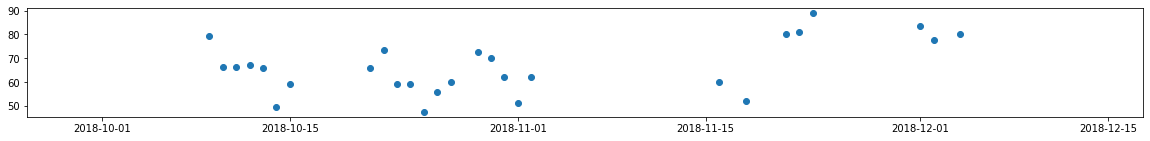

In [36]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_subset = df_vitals_hr_day[df_vitals_hr_day['patient_uuid'] == 82591262]
df_vitals_subset = df_vitals_subset[['reading_date','HR']]
pyplot.scatter(df_vitals_subset['reading_date'],df_vitals_subset['HR'])
pyplot.show()

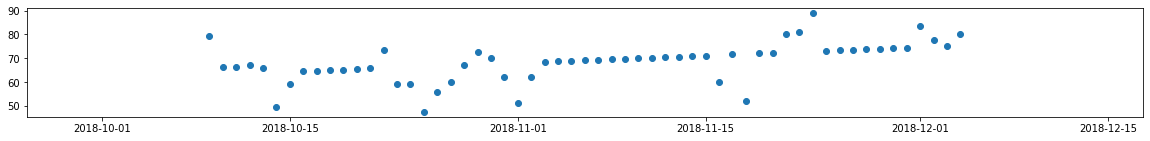

In [37]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_interpolated_subset = df_vitals_interpolated_final[df_vitals_interpolated_final['patient_uuid'] == 82591262]
df_vitals_interpolated_subset = df_vitals_interpolated_subset[['reading_date','HR']]
pyplot.scatter(df_vitals_interpolated_subset['reading_date'],df_vitals_interpolated_subset['HR'])
pyplot.show()

In [38]:
df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','HR']]

In [39]:
df_vitals_hr_minmaxtimes = pd.DataFrame(df_vitals_interpolated_final.groupby('patient_uuid').agg({'reading_date' : np.min}))

df_vitals_hr_minmaxtimes.rename(columns={'reading_date':'reading_start_date'},inplace=True)

df_vitals_interpolated_final = pd.merge(df_vitals_interpolated_final, df_vitals_hr_minmaxtimes, on='patient_uuid')

df_vitals_interpolated_final['reading_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_date'])
df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final.sort_values(by=['patient_uuid','reading_date'],inplace=True)


df_vitals_interpolated_final

,patient_uuid,reading_date,HR,reading_start_date
0,1048697,2019-08-26,80.000000,2019-08-26
1,1048697,2019-08-27,92.666667,2019-08-26
2,1048697,2019-08-28,84.500000,2019-08-26
3,1048697,2019-08-29,84.333333,2019-08-26
4,1048697,2019-08-30,91.500000,2019-08-26
...,...,...,...,...
153957,99814066,2020-01-08,97.283923,2020-01-08
153958,99814066,2020-01-09,93.460395,2020-01-08
153959,99814066,2020-01-10,89.636867,2020-01-08
153960,99814066,2020-01-11,85.813338,2020-01-08


In [40]:
df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days


In [41]:
df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','HR']]

In [42]:
df_vitals_interpolated_final.to_csv("vitals_hr_interpolated.csv", index = False)

In [46]:
vitals_hr_interpolated = pd.read_csv('vitals_hr_interpolated.csv')

In [44]:
vitals_hr_interpolated['reading_date'] = pd.to_datetime(vitals_hr_interpolated['reading_date'])
vitals_hr_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in vitals_hr_interpolated['patient_uuid'].unique():
    vitals_hr_interpolated_patient = vitals_hr_interpolated[vitals_hr_interpolated['patient_uuid']==patient_uuid]
    for batch in vitals_hr_interpolated_patient['batch'].unique():
        vitals_hr_interpolated_patient_batch = vitals_hr_interpolated_patient[vitals_hr_interpolated_patient['batch']==batch]
        vitals_hr_interpolated_patient_batch['reading_date'] = pd.to_datetime(vitals_hr_interpolated_patient_batch['reading_date'])
        vitals_hr_interpolated_patient_batch['next_reading_date'] = vitals_hr_interpolated_patient_batch['reading_date'].shift(-1)
        #print(int((vitals_hr_interpolated_patient_batch['next_reading_date'] - vitals_hr_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
        vitals_hr_interpolated_patient_batch['days_difference'] = (vitals_hr_interpolated_patient_batch['next_reading_date'] - vitals_hr_interpolated_patient_batch['reading_date'])
        #print(vitals_hr_interpolated_patient_batch.dtypes)
        row_count_with_days_diff = vitals_hr_interpolated_patient_batch[vitals_hr_interpolated_patient_batch['days_difference']>timedelta(days=1)].shape[0]
        if row_count_with_days_diff > 0:
            print(vitals_hr_interpolated_patient_batch[vitals_hr_interpolated_patient_batch['days_difference']>timedelta(days=1)])
    #break

In [45]:
vitals_hr_interpolated['reading_date'] = pd.to_datetime(vitals_hr_interpolated['reading_date'])
vitals_hr_interpolated.sort_values(by=['patient_uuid','reading_date','batch'],inplace=True)
for patient_uuid in vitals_hr_interpolated['patient_uuid'].unique():
    vitals_hr_interpolated_patient = vitals_hr_interpolated[vitals_hr_interpolated['patient_uuid']==patient_uuid]
    vitals_hr_interpolated_patient['reading_date'] = pd.to_datetime(vitals_hr_interpolated_patient['reading_date'])
    vitals_hr_interpolated_patient['next_reading_date'] = vitals_hr_interpolated_patient['reading_date'].shift(-1)
    #print(int((vitals_hr_interpolated_patient_batch['next_reading_date'] - vitals_hr_interpolated_patient_batch['reading_date']).to_string().split(' ')[0]))
    vitals_hr_interpolated_patient['days_difference'] = (vitals_hr_interpolated_patient['next_reading_date'] - vitals_hr_interpolated_patient['reading_date'])
    #print(vitals_hr_interpolated_patient_batch.dtypes)
    row_count_with_days_diff = vitals_hr_interpolated_patient[(vitals_hr_interpolated_patient['days_difference']>timedelta(days=1))&(vitals_hr_interpolated_patient['days_difference']<timedelta(days=16))].shape[0]
    if row_count_with_days_diff > 0:
        print(vitals_hr_interpolated_patient[(vitals_hr_interpolated_patient['days_difference']>timedelta(days=1))&(vitals_hr_interpolated_patient['days_difference']<timedelta(days=16))])
    #break